# USA: Target sectors and national factors (2014–2024)

This notebook investigates how documented cyber incidents are distributed across US target sectors, whether that composition changes over time, and how sector shares relate to economic and digital indicators.

**Research questions**

- **Q1:** Which target sectors account for the largest shares of documented incidents?
- **Q2:** Does the sector composition of documented incidents differ across years?
- **Q3:** Do selected sectors (especially Public Administration) differ in their representation among documented incidents?
- **Q4:** Has sector concentration changed over time?
- **Q5:** Is sector composition associated with the industry and services shares of GDP?
- **Q6:** Is sector composition associated with digital adoption and economic development?

**Sources:** [UMD Cyber Events Database](https://gotech.umd.edu/research-impact/publications/cyber-events-database-home); [World Bank WDI](https://data.worldbank.org/); [BEA](https://www.bea.gov/); [BLS QCEW](https://www.bls.gov/cew/).

## 1. Data and scope

Load the previously deduplicated US UMD incident records and the annual national-factor table. Confirm coverage, sector labels, and the correct unit of analysis.

In [1]:
# Imports
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

from scipy.stats import binomtest, chi2_contingency, spearmanr , norm
from statsmodels.stats.multitest import multipletests

### 1.1 Data sources and coverage

Inspect years, duplicate identifiers, missing or undetermined sectors, and the annual data intersection.

<div style="text-align: center; font-weight: bold; font-style: italic;">
What is the temporal coverage of the UMD incident data and national factors, and are the datasets suitable for a consistent annual sector analysis?
</div>

We examine annual record counts, missing sector classifications, and the years available in both datasets before selecting the analysis period.



In [2]:
def find_project_root(start):
    for directory in (start, *start.parents):
        if (directory / "data" / "processed" / "umd_usa").is_dir():
            return directory
    raise FileNotFoundError("Could not locate the USA project root.")


ROOT = find_project_root(Path.cwd())

umd = pd.read_csv(
    ROOT / "data/processed/umd_usa/umd_usa_deduplicated_consolidated.csv",
    low_memory=False,
)

factors = pd.read_csv(
    ROOT / "data/processed/factors/usa_national_factors_2014_2025.csv"
)

print(f"UMD: {len(umd):,} records, {len(umd.columns)} columns")
print(f"National factors: {len(factors):,} rows")


UMD: 8,203 records, 49 columns
National factors: 12 rows


In [3]:
annual_coverage = (
    umd.groupby("year")
    .agg(
        incidents=("slug", "size"),
        unique_ids=("slug", "nunique"),
        missing_sectors=("industry", lambda x: x.isna().sum()),
        undetermined_sectors=(
            "industry",
            lambda x: x.astype("string").str.strip().eq("Undetermined").sum()
        ),
    )
    .reset_index()
)

annual_coverage["factors_available"] = (
    annual_coverage["year"].isin(factors["year"])
)

display(annual_coverage)


,year,incidents,unique_ids,missing_sectors,undetermined_sectors,factors_available
0,2014,283,283,0,7,True
1,2015,380,380,0,2,True
2,2016,456,456,0,6,True
3,2017,366,366,0,3,True
4,2018,450,450,0,0,True
5,2019,590,590,0,0,True
6,2020,927,927,0,17,True
7,2021,724,724,0,3,True
8,2022,933,933,0,2,True
9,2023,1388,1388,0,4,True



### 1.2 Sector classifications

<div style="text-align: center; font-weight: bold; font-style: italic;">
 Which target-sector categories are present in the UMD dataset, and how many documented incidents belong to each category?
</div>


We inspect sector labels and frequencies to determine whether categories are suitable for sector comparisons, concentration measures, and statistical tests.


In [4]:
umd_analysis = umd.loc[
    umd["year"].between(2014, 2024)
].copy()

sector_counts = (
    umd_analysis["industry"]
    .value_counts(dropna=False)
    .rename_axis("sector")
    .reset_index(name="incidents")
)

sector_counts["share_pct"] = (
    100 * sector_counts["incidents"] / len(umd_analysis)
)

display(
    sector_counts.round({"share_pct": 2})
)


,sector,incidents,share_pct
0,Health Care and Social Assistance,1652,23.17
1,Educational Services,925,12.98
2,Public Administration,911,12.78
3,"Professional, Scientific, and Technical Services",692,9.71
4,Information,598,8.39
5,Finance and Insurance,546,7.66
6,Other Services (except Public Administration),379,5.32
7,Manufacturing,283,3.97
8,"Arts, Entertainment, and Recreation",228,3.20
9,Retail Trade,225,3.16



### 1.3 Annual sector indicators

<div style="text-align: center; font-weight: bold; font-style: italic;">
 How are documented incidents distributed across target sectors in each year from 2014 to 2024?
 </div>

We calculate annual incident counts and sector shares, excluding records with undetermined sector classifications. These indicators form the basis for subsequent statistical tests and concentration analysis.


In [5]:
umd_known = umd_analysis.loc[
    umd_analysis["industry"].ne("Undetermined")
].copy()

annual_sector_counts = pd.crosstab(
    umd_known["year"],
    umd_known["industry"]
)

annual_sector_shares = (
    annual_sector_counts
    .div(annual_sector_counts.sum(axis=1), axis=0)
    * 100
)

print("Known-sector incidents:", len(umd_known))
print("Number of sectors:", len(annual_sector_counts.columns))
print("Years:", annual_sector_counts.index.min(), "-", annual_sector_counts.index.max())


Known-sector incidents: 7070
Number of sectors: 20
Years: 2014 - 2024


In [6]:
top_sectors = sector_counts.loc[
    sector_counts["sector"].ne("Undetermined"),
    "sector"
].head(6).tolist()

display(
    annual_sector_shares[top_sectors]
    .round(2)
    .rename_axis("year")
)


industry,Health Care and Social Assistance,Educational Services,Public Administration,"Professional, Scientific, and Technical Services",Information,Finance and Insurance
year,,,,,,
2014,6.16,10.14,11.96,5.80,23.91,2.17
2015,6.08,13.23,16.14,2.38,25.13,4.23
2016,7.56,6.89,15.33,16.00,16.00,4.67
2017,15.70,14.05,14.33,9.92,12.67,3.58
2018,24.00,13.11,17.56,2.67,8.89,4.89
2019,24.92,17.12,19.66,7.46,5.08,4.07
2020,23.52,18.35,14.73,10.00,7.14,4.40
2021,33.01,14.98,10.26,9.85,6.10,4.44
2022,28.25,10.74,8.38,11.82,4.83,9.45


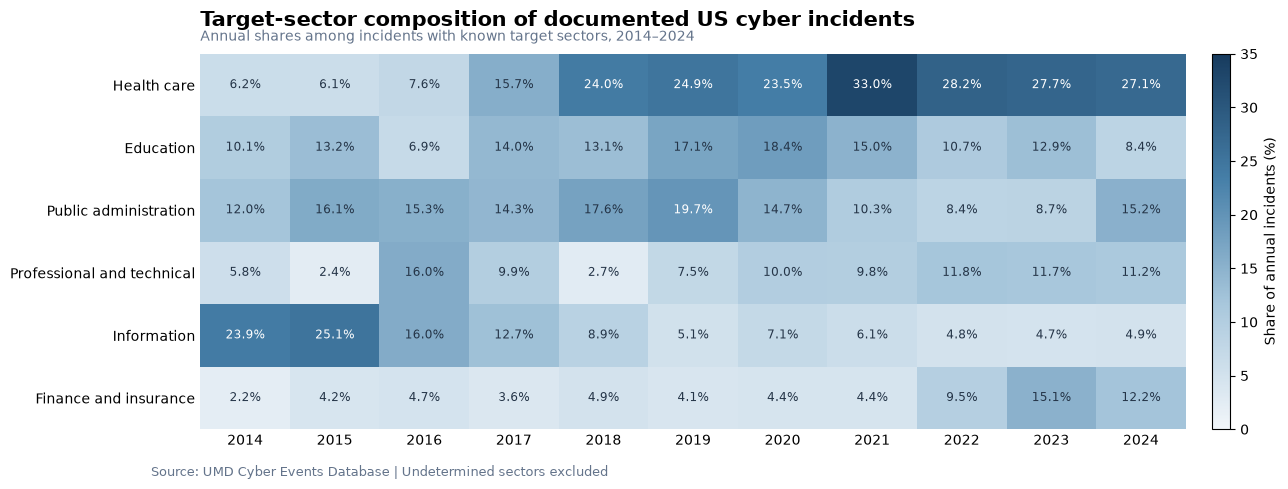

In [7]:
sector_labels = {
    "Health Care and Social Assistance": "Health care",
    "Educational Services": "Education",
    "Public Administration": "Public administration",
    "Professional, Scientific, and Technical Services": "Professional and technical",
    "Information": "Information",
    "Finance and Insurance": "Finance and insurance",
}

plot_data = annual_sector_shares[top_sectors].T
plot_data.index = [
    sector_labels.get(sector, sector)
    for sector in plot_data.index
]

cmap = LinearSegmentedColormap.from_list(
    "sector_blue",
    ["#F2F6FA", "#A8C7DC", "#467FA8", "#173B5E"]
)

fig, ax = plt.subplots(figsize=(13, 5.2))

im = ax.imshow(
    plot_data,
    cmap=cmap,
    aspect="auto",
    vmin=0,
    vmax=np.ceil(plot_data.to_numpy().max() / 5) * 5
)

ax.set_xticks(np.arange(len(plot_data.columns)))
ax.set_xticklabels(plot_data.columns, fontsize=10)

ax.set_yticks(np.arange(len(plot_data.index)))
ax.set_yticklabels(plot_data.index, fontsize=10)

ax.set_title(
    "Target-sector composition of documented US cyber incidents",
    fontsize=15,
    fontweight="bold",
    loc="left",
    pad=20
)

ax.text(
    0, 1.035,
    "Annual shares among incidents with known target sectors, 2014–2024",
    transform=ax.transAxes,
    fontsize=10,
    color="#64748B"
)

for i in range(plot_data.shape[0]):
    for j in range(plot_data.shape[1]):
        value = plot_data.iloc[i, j]
        ax.text(
            j, i, f"{value:.1f}%",
            ha="center",
            va="center",
            fontsize=8.5,
            color="white" if value > 0.55 * im.norm.vmax else "#243447"
        )

ax.tick_params(axis="both", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.025)
cbar.set_label("Share of annual incidents (%)", fontsize=10)

fig.text(
    0.12, 0.015,
    "Source: UMD Cyber Events Database | Undetermined sectors excluded",
    fontsize=9,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.04, 1, 0.94])
plt.show()



The composition of documented US cyber incidents changed substantially between 2014 and 2024. Health care gained a larger share, while the Information sector became less prominent. Public Administration fluctuated considerably, and Finance and Insurance gained share in recent years. Statistical testing is needed to establish whether the overall sector distribution differs across years.



## 2. Sector composition over time

We examine whether the distribution of documented cyber incidents across target sectors differs between 2014 and 2024.

### 2.1 Chi-square test of independence
<div style="text-align: center; font-weight: bold; font-style: italic;">

 Is the distribution of documented cyber incidents across target sectors associated with year?

</div>

We use the chi-square test of independence and report Cramér's V to quantify the strength of the association. Before interpreting the test, we examine expected cell frequencies.


<div style="text-align: center; font-weight: bold; font-style: italic;">

**H₀ :** Target sector and year are independent.

**H₁:** Target sector and year are associated.

</div>


In [8]:
chi2, p_value, dof, expected = chi2_contingency(
    annual_sector_counts,
    correction=False
)

expected_below_5 = (expected < 5).sum()
expected_below_1 = (expected < 1).sum()
total_cells = expected.size

print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"Nominal p-value: {p_value:.3e}")
print(f"Minimum expected frequency: {expected.min():.3f}")
print(f"Cells with expected frequency < 5: {expected_below_5}/{total_cells}")
print(f"Cells with expected frequency < 1: {expected_below_1}/{total_cells}")
print(f"Percentage of cells below 5: {100 * expected_below_5 / total_cells:.1f}%")


Chi-square statistic: 1649.427
Degrees of freedom: 190
Nominal p-value: 9.550e-231
Minimum expected frequency: 0.234
Cells with expected frequency < 5: 67/220
Cells with expected frequency < 1: 22/220
Percentage of cells below 5: 30.5%



**Preliminary results and methodological considerations**

The initial chi-square test of independence was performed using all 20 known target sectors across 11 years (2014–2024).

The test produced $\chi^2(190) = 1649.427$ and a nominal $p$-value of $9.55 \times 10^{-231}$. However, 67 of 220 cells (30.5%) had expected frequencies below 5, including 22 cells below 1. The minimum expected frequency was 0.234.

These results indicate that the usual chi-square approximation may be unreliable. Therefore, the nominal p-value is retained for transparency but is not treated as a definitive inferential result.

We will proceed by retaining major, substantively important sectors and combining infrequent sectors into an "Other sectors" category. The grouping will be documented and evaluated using expected cell frequencies before interpreting the revised test.

The original 20-sector classification will remain unchanged for descriptive analyses, individual sector comparisons, and the Herfindahl–Hirschman Index.


In [9]:
# Check expected frequencies by sector to identify categories that may need grouping.
expected_df = pd.DataFrame(
    expected,
    index=annual_sector_counts.index,
    columns=annual_sector_counts.columns
)

sector_diagnostics = pd.DataFrame({
    "total_incidents": annual_sector_counts.sum(axis=0),
    "min_expected": expected_df.min(axis=0),
    "cells_below_5": (expected_df < 5).sum(axis=0),
    "cells_below_1": (expected_df < 1).sum(axis=0)
})

sector_diagnostics = sector_diagnostics.sort_values(
    "total_incidents",
    ascending=False
)

display(sector_diagnostics.round(2))


,total_incidents,min_expected,cells_below_5,cells_below_1
industry,,,,
Health Care and Social Assistance,1652,64.49,0,0
Educational Services,925,36.11,0,0
Public Administration,911,35.56,0,0
"Professional, Scientific, and Technical Services",692,27.01,0,0
Information,598,23.34,0,0
Finance and Insurance,546,21.31,0,0
Other Services (except Public Administration),379,14.80,0,0
Manufacturing,283,11.05,0,0
"Arts, Entertainment, and Recreation",228,8.90,0,0



### 2.2 Chi-square test with grouped sectors

To address low expected frequencies in the original 20-sector contingency table, we retain the 11 most frequent sectors and combine the remaining nine into "Other sectors".

This grouping preserves the original classification of the major sectors while reducing sparse cells. We then repeat the chi-square test of independence and calculate Cramér's V.


In [10]:
# Retain the 11 most frequent sectors and group the remaining categories.

major_sectors = sector_counts.loc[
    sector_counts["sector"].ne("Undetermined"),
    "sector"
].head(11).tolist()

umd_grouped = umd_known.copy()

umd_grouped["sector_group"] = (
    umd_grouped["industry"]
    .where(umd_grouped["industry"].isin(major_sectors), "Other sectors")
)

grouped_counts = pd.crosstab(
    umd_grouped["year"],
    umd_grouped["sector_group"]
)

print(f"Original sectors: {annual_sector_counts.shape[1]}")
print(f"Grouped categories: {grouped_counts.shape[1]}")
print(f"Incidents retained: {grouped_counts.to_numpy().sum():,}")
print(f"Incidents in Other sectors: {(umd_grouped['sector_group'] == 'Other sectors').sum():,}")


Original sectors: 20
Grouped categories: 12
Incidents retained: 7,070
Incidents in Other sectors: 442


In [11]:
# Repeat the chi-square test and check expected frequencies after grouping.

chi2_grouped, p_grouped, dof_grouped, expected_grouped = (
    chi2_contingency(grouped_counts, correction=False)
)

n = grouped_counts.to_numpy().sum()
r, c = grouped_counts.shape

cramers_v = np.sqrt(
    chi2_grouped / (n * min(r - 1, c - 1))
)

print(f"Chi-square statistic: {chi2_grouped:.3f}")
print(f"Degrees of freedom: {dof_grouped}")
print(f"Nominal p-value: {p_grouped:.3e}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Minimum expected frequency: {expected_grouped.min():.3f}")
print(f"Cells below 5: {(expected_grouped < 5).sum()}/{expected_grouped.size}")
print(f"Cells below 1: {(expected_grouped < 1).sum()}/{expected_grouped.size}")


Chi-square statistic: 1541.300
Degrees of freedom: 110
Nominal p-value: 7.405e-251
Cramer's V: 0.148
Minimum expected frequency: 7.378
Cells below 5: 0/132
Cells below 1: 0/132



**Results and interpretation**

After retaining the 11 most frequent sectors and grouping the remaining nine into "Other sectors", the contingency table contained 12 sector categories and 7,070 incidents.

All expected frequencies exceeded 5 (minimum = 7.378), addressing the sparse-cell issue identified in the original analysis.

The chi-square test showed a statistically significant association between year and target sector, χ²(110) = 1541.300, p < 0.001. However, Cramér's V = 0.148 indicates a relatively weak overall association.

Therefore, the sector composition of publicly documented US cyber incidents differed across years during 2014–2024. This result does not establish changes in sector-specific attack risk or causality. Possible dependence between incidents belonging to the same campaign remains a limitation.


In [12]:
# Retain the 13 most frequent sectors and group the remaining categories.

major_sectors = sector_counts.loc[
    sector_counts["sector"].ne("Undetermined"),
    "sector"
].head(13).tolist()

umd_grouped = umd_known.copy()

umd_grouped["sector_group"] = (
    umd_grouped["industry"]
    .where(umd_grouped["industry"].isin(major_sectors), "Other sectors")
)

grouped_counts = pd.crosstab(
    umd_grouped["year"],
    umd_grouped["sector_group"]
)

print(f"Original sectors: {annual_sector_counts.shape[1]}")
print(f"Grouped categories: {grouped_counts.shape[1]}")
print(f"Incidents retained: {grouped_counts.to_numpy().sum():,}")
print(f"Incidents in Other sectors: {(umd_grouped['sector_group'] == 'Other sectors').sum():,}")


Original sectors: 20
Grouped categories: 14
Incidents retained: 7,070
Incidents in Other sectors: 219


In [13]:
# Repeat the chi-square test and check expected frequencies after grouping.

chi2_grouped, p_grouped, dof_grouped, expected_grouped = (
    chi2_contingency(grouped_counts, correction=False)
)

n = grouped_counts.to_numpy().sum()
r, c = grouped_counts.shape

cramers_v = np.sqrt(
    chi2_grouped / (n * min(r - 1, c - 1))
)

print(f"Chi-square statistic: {chi2_grouped:.3f}")
print(f"Degrees of freedom: {dof_grouped}")
print(f"Nominal p-value: {p_grouped:.3e}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Minimum expected frequency: {expected_grouped.min():.3f}")
print(f"Cells below 5: {(expected_grouped < 5).sum()}/{expected_grouped.size}")
print(f"Cells below 1: {(expected_grouped < 1).sum()}/{expected_grouped.size}")


Chi-square statistic: 1566.632
Degrees of freedom: 130
Nominal p-value: 9.032e-245
Cramer's V: 0.149
Minimum expected frequency: 4.138
Cells below 5: 2/154
Cells below 1: 0/154



**Sensitivity analysis: retaining 13 major sectors**

We repeated the chi-square test while retaining the 13 most frequent sectors and grouping the remaining seven into "Other sectors".

The resulting table contained 14 categories and 7,070 incidents, with only 219 incidents (3.10%) assigned to the grouped category.

**The chi-square test remained statistically significant, χ²(130) = 1566.632, p < 0.001, with Cramér's V = 0.149. Only 2 of 154 cells (1.3%) had expected frequencies below 5, and none had expected frequencies below 1.**

The association between year and target sector was therefore consistent across the 11-sector and 13-sector grouping strategies. We retain 13 major sectors for the primary analysis and use the 11-sector grouping as a sensitivity check. Possible dependence among incidents remains a limitation.


### 2.3 Identifying sector-year deviations

<div style="text-align: center; font-weight: bold; font-style: italic;">
Which target sectors and years show significantly more or fewer documented cyber incidents than expected?
</div>

While the chi-square test confirms an overall association between year and sector, it does not identify specific deviations. We therefore calculate **adjusted standardized residuals** across 14 sector categories (the 13 largest plus "Other sectors").

**Hypotheses:**
* **$H_0$:** The observed incident count matches the expected count under independence.
* **$H_1$:** The observed incident count differs from the expected count.

**Method:**
For each sector-year cell, we compute the expected count ($E_{ij}$) and the adjusted standardized residual ($r_{ij}^{adj}$):

$$
E_{ij} = \frac{n_{i\cdot}n_{\cdot j}}{N}, \quad r_{ij}^{adj} = \frac{O_{ij}-E_{ij}}{\sqrt{E_{ij}(1-n_{i\cdot}/N)(1-n_{\cdot j}/N)}}
$$

*(where $O_{ij}$ is the observed count, $n_{i\cdot}$ and $n_{\cdot j}$ are row and column totals, and $N$ is the total number of incidents).*

* **Positive residuals** indicate more incidents than expected; **negative residuals** indicate fewer.
* Since adjusted residuals follow an approximate standard normal distribution, we compute two-sided $p$-values and apply the **Holm correction** across all 154 comparisons to control for multiple testing.

**Limitations:** These results reflect shifts in the composition of documented incidents rather than actual sector-specific cyber risk, and potential clustering of incidents within single campaigns remains a limitation.

In [14]:
# Calculate adjusted standardized residuals for each sector-year combination.

observed = grouped_counts.to_numpy(dtype=float)

row_totals = observed.sum(axis=1, keepdims=True)
col_totals = observed.sum(axis=0, keepdims=True)
total = observed.sum()

expected_residuals = row_totals @ col_totals / total

adjustment = (
    (1 - row_totals / total)
    * (1 - col_totals / total)
)

adjusted_residuals = (
    (observed - expected_residuals)
    / np.sqrt(expected_residuals * adjustment)
)

residuals_df = pd.DataFrame(
    adjusted_residuals,
    index=grouped_counts.index,
    columns=grouped_counts.columns
)

print(f"Sector-year combinations: {adjusted_residuals.size}")
print(f"Minimum residual: {adjusted_residuals.min():.3f}")
print(f"Maximum residual: {adjusted_residuals.max():.3f}")


Sector-year combinations: 154
Minimum residual: -8.191
Maximum residual: 13.167


In [15]:
# Test cell-level deviations and correct for multiple comparisons.

raw_p_values = 2 * norm.sf(np.abs(adjusted_residuals))

reject, adjusted_p_values, _, _ = multipletests(
    raw_p_values.ravel(),
    alpha=0.05,
    method="holm"
)

residual_results = pd.DataFrame({
    "year": np.repeat(grouped_counts.index.to_numpy(), grouped_counts.shape[1]),
    "sector": np.tile(grouped_counts.columns.to_numpy(), grouped_counts.shape[0]),
    "observed": observed.ravel().astype(int),
    "expected": expected_residuals.ravel(),
    "adjusted_residual": adjusted_residuals.ravel(),
    "p_value": raw_p_values.ravel(),
    "p_adjusted": adjusted_p_values,
    "significant": reject
})

print(f"Total comparisons: {len(residual_results)}")
print(f"Significant deviations after Holm correction: {reject.sum()}")
print(f"Positive significant deviations: {((reject) & (adjusted_residuals.ravel() > 0)).sum()}")
print(f"Negative significant deviations: {((reject) & (adjusted_residuals.ravel() < 0)).sum()}")


Total comparisons: 154
Significant deviations after Holm correction: 39
Positive significant deviations: 19
Negative significant deviations: 20


In [16]:
# Display the strongest significant deviations in either direction.

top_deviations = (
    residual_results.loc[residual_results["significant"]]
    .assign(abs_residual=lambda df: df["adjusted_residual"].abs())
    .sort_values("abs_residual", ascending=False)
    .head(15)
    .drop(columns="abs_residual")
)

display(
    top_deviations.round({
        "expected": 1,
        "adjusted_residual": 2,
        "p_value": 5,
        "p_adjusted": 5
    })
)


,year,sector,observed,expected,adjusted_residual,p_value,p_adjusted,significant
36,2016,Other Services (except Public Administration),85,24.1,13.17,0.0,0.00000,True
20,2015,Information,95,32.0,11.97,0.0,0.00000,True
130,2023,Finance and Insurance,209,106.9,11.47,0.0,0.00000,True
6,2014,Information,66,23.3,9.41,0.0,0.00000,True
119,2022,Manufacturing,84,37.3,8.39,0.0,0.00000,True
33,2016,Health Care and Social Assistance,34,105.1,-8.19,0.0,0.00000,True
19,2015,Health Care and Social Assistance,23,88.3,-8.16,0.0,0.00000,True
5,2014,Health Care and Social Assistance,17,64.5,-6.89,0.0,0.00000,True
8,2014,Other Services (except Public Administration),40,14.8,6.87,0.0,0.00000,True
103,2021,Health Care and Social Assistance,238,168.5,6.46,0.0,0.00000,True



**Results and interpretation**

Among 154 sector-year combinations, 39 showed statistically significant deviations after Holm correction (19 positive and 20 negative), under the approximate independent-observation model.

The largest positive deviations occurred in Other Services in 2016 (85 observed vs. 24.1 expected), Information in 2015 (95 vs. 32.0), and Finance and Insurance in 2023 (209 vs. 106.9).

Health Care and Social Assistance was substantially underrepresented relative to the independence model in 2014–2016, but overrepresented in 2021 (238 vs. 168.5).

These results identify changes in the composition of documented incidents rather than changes in underlying sector-specific attack risk. Campaign-level clustering and changes in reporting practices may affect statistical inference.


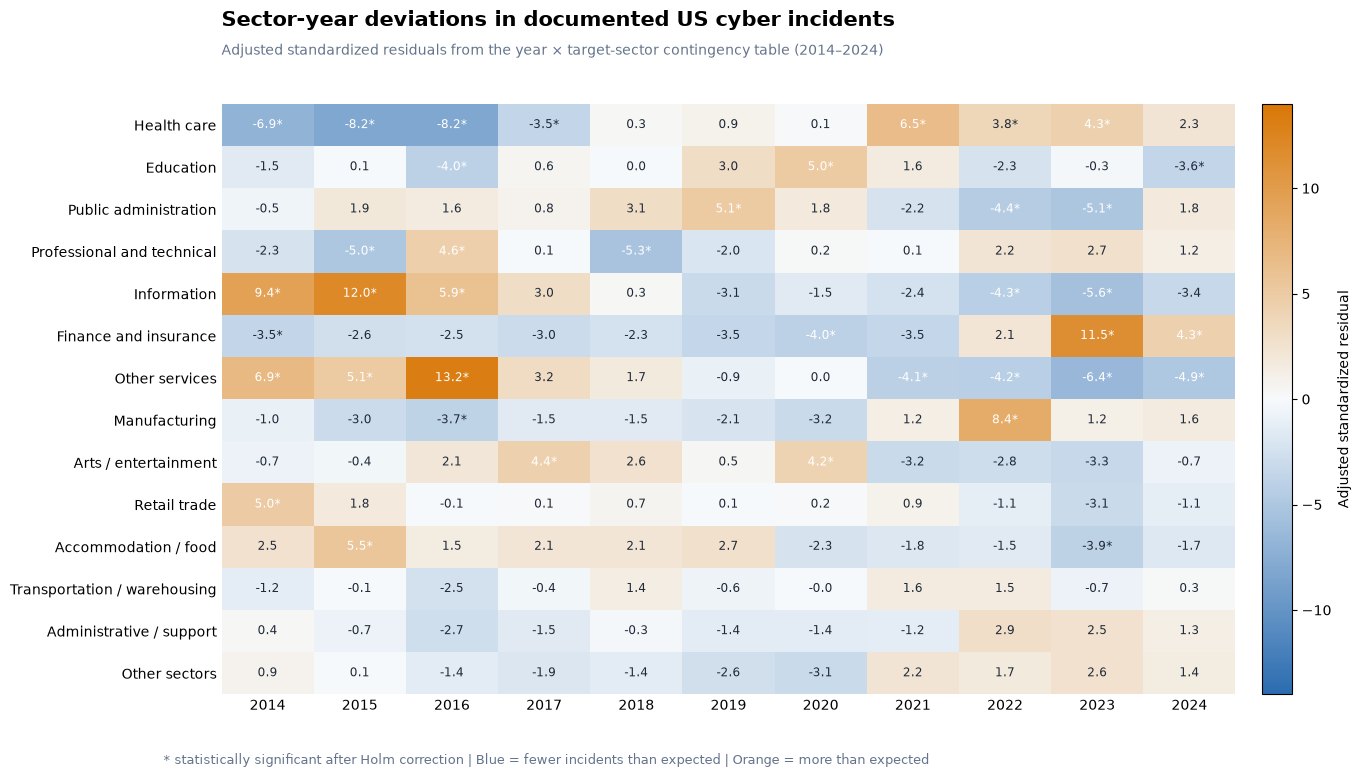

In [17]:

# Visualize adjusted standardized residuals for sector-year combinations.

sector_order = (
    grouped_counts.sum(axis=0)
    .sort_values(ascending=False)
    .index
    .tolist()
)

if "Other sectors" in sector_order:
    sector_order = [s for s in sector_order if s != "Other sectors"] + ["Other sectors"]

sector_labels = {
    "Health Care and Social Assistance": "Health care",
    "Educational Services": "Education",
    "Public Administration": "Public administration",
    "Professional, Scientific, and Technical Services": "Professional and technical",
    "Information": "Information",
    "Finance and Insurance": "Finance and insurance",
    "Other Services (except Public Administration)": "Other services",
    "Manufacturing": "Manufacturing",
    "Arts, Entertainment, and Recreation": "Arts / entertainment",
    "Retail Trade": "Retail trade",
    "Accommodation and Food Services": "Accommodation / food",
    "Transportation and Warehousing": "Transportation / warehousing",
    "Administrative and Support and Waste Management and Remediation Services": "Administrative / support",
    "Other sectors": "Other sectors",
}

plot_residuals = residuals_df[sector_order].T
plot_residuals.index = [
    sector_labels.get(s, s) for s in plot_residuals.index
]

significance_matrix = (
    residual_results
    .pivot(index="sector", columns="year", values="significant")
    .loc[sector_order]
)
significance_matrix.index = [
    sector_labels.get(s, s) for s in significance_matrix.index
]

max_abs_residual = np.ceil(np.abs(plot_residuals.to_numpy()).max())

cmap = LinearSegmentedColormap.from_list(
    "residuals_diverging",
    ["#2B6CB0", "#F7FAFC", "#D97706"]
)

norm = TwoSlopeNorm(
    vmin=-max_abs_residual,
    vcenter=0,
    vmax=max_abs_residual
)

fig, ax = plt.subplots(figsize=(14.5, 8.2))

im = ax.imshow(
    plot_residuals,
    cmap=cmap,
    norm=norm,
    aspect="auto"
)

ax.set_xticks(np.arange(len(plot_residuals.columns)))
ax.set_xticklabels(plot_residuals.columns, fontsize=10)

ax.set_yticks(np.arange(len(plot_residuals.index)))
ax.set_yticklabels(plot_residuals.index, fontsize=10)

# Place title and subtitle in separate figure-level positions.
fig.text(
    0.16, 0.955,
    "Sector-year deviations in documented US cyber incidents",
    fontsize=15,
    fontweight="bold",
    ha="left"
)

fig.text(
    0.16, 0.920,
    "Adjusted standardized residuals from the year × target-sector contingency table (2014–2024)",
    fontsize=10,
    color="#64748B",
    ha="left"
)

for i in range(plot_residuals.shape[0]):
    for j in range(plot_residuals.shape[1]):
        value = plot_residuals.iloc[i, j]
        is_significant = significance_matrix.iloc[i, j]

        text_color = "white" if abs(value) >= 4 else "#1F2937"
        label = f"{value:.1f}"

        if is_significant:
            label += "*"

        ax.text(
            j, i, label,
            ha="center",
            va="center",
            fontsize=8.3,
            color=text_color
        )

ax.tick_params(axis="both", length=0)

for spine in ax.spines.values():
    spine.set_visible(False)

cbar = fig.colorbar(
    im, ax=ax,
    fraction=0.03,
    pad=0.025
)
cbar.set_label(
    "Adjusted standardized residual",
    fontsize=10
)

# Reserve dedicated space for the header and footer.
fig.subplots_adjust(
    left=0.16,
    right=0.90,
    top=0.86,
    bottom=0.14
)

fig.text(
    0.12, 0.055,
    "* statistically significant after Holm correction | Blue = fewer incidents than expected | Orange = more than expected",
    fontsize=9,
    color="#64748B"
)

figure_name = "03_adjusted_residuals_heatmap_2014_2024.png"

for output_dir in [
    ROOT / "figures/factors/static",
    ROOT / "ugotovitve/dejavnike",
]:
    output_dir.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        output_dir / figure_name,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()



## 3. Sector-level comparisons

### 3.1 Comparing Public Administration with other sectors

<div style="text-align: center; font-weight: bold; font-style: italic;">
Does Public Administration account for a significantly different number of documented cyber incidents than other major target sectors?
</div>


We compare the frequency of documented incidents in Public Administration with each of the other major sectors over 2014–2024.

For each pair of sectors, we test:

- **H₀:** The two sectors are equally represented among incidents assigned to either sector.
- **H₁:** The two sectors are not equally represented.

We use two-sided exact binomial tests, conditional on the total number of incidents in each sector pair. Holm correction is applied to account for multiple comparisons.

These tests assess relative representation within the UMD dataset, not sector-specific attack risk. They assume that incident observations can be treated as independent and that the sector classification is mutually exclusive.


In [18]:
# Compare Public Administration with other major sectors using exact binomial tests.

reference_sector = "Public Administration"

known_sector_counts = (
    umd_known["industry"]
    .value_counts()
)

reference_count = int(known_sector_counts[reference_sector])

comparison_sectors = [
    sector for sector in major_sectors
    if sector != reference_sector
]

comparison_results = []

for sector in comparison_sectors:
    sector_count = int(known_sector_counts[sector])
    pair_total = reference_count + sector_count

    result = binomtest(
        k=reference_count,
        n=pair_total,
        p=0.5,
        alternative="two-sided"
    )

    comparison_results.append({
        "comparison_sector": sector,
        "public_administration": reference_count,
        "other_sector": sector_count,
        "difference": reference_count - sector_count,
        "p_value": result.pvalue
    })

sector_comparisons = pd.DataFrame(comparison_results)

sector_comparisons["p_adjusted"] = multipletests(
    sector_comparisons["p_value"],
    method="holm"
)[1]

sector_comparisons["significant"] = (
    sector_comparisons["p_adjusted"] < 0.05
)

display(
    sector_comparisons
    .sort_values("difference", ascending=False)
    .round({"p_value": 5, "p_adjusted": 5})
)


,comparison_sector,public_administration,other_sector,difference,p_value,p_adjusted,significant
11,Administrative and Support and Waste Managemen...,911,106,805,0.0000,0.0000,True
10,Transportation and Warehousing,911,117,794,0.0000,0.0000,True
9,Accommodation and Food Services,911,189,722,0.0000,0.0000,True
8,Retail Trade,911,225,686,0.0000,0.0000,True
7,"Arts, Entertainment, and Recreation",911,228,683,0.0000,0.0000,True
6,Manufacturing,911,283,628,0.0000,0.0000,True
5,Other Services (except Public Administration),911,379,532,0.0000,0.0000,True
4,Finance and Insurance,911,546,365,0.0000,0.0000,True
3,Information,911,598,313,0.0000,0.0000,True
2,"Professional, Scientific, and Technical Services",911,692,219,0.0000,0.0000,True


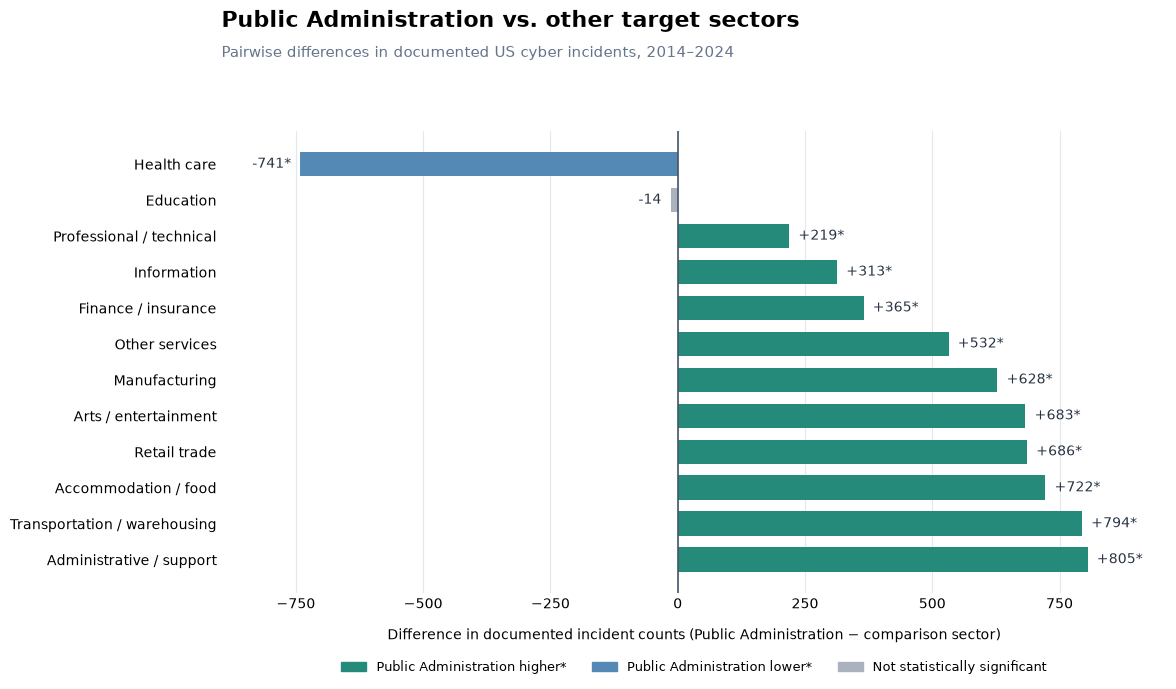

In [19]:
# Visualize pairwise incident-count differences relative to Public Administration.

sector_short_names = {
    "Health Care and Social Assistance": "Health care",
    "Educational Services": "Education",
    "Professional, Scientific, and Technical Services": "Professional / technical",
    "Information": "Information",
    "Finance and Insurance": "Finance / insurance",
    "Other Services (except Public Administration)": "Other services",
    "Manufacturing": "Manufacturing",
    "Arts, Entertainment, and Recreation": "Arts / entertainment",
    "Retail Trade": "Retail trade",
    "Accommodation and Food Services": "Accommodation / food",
    "Transportation and Warehousing": "Transportation / warehousing",
    "Administrative and Support and Waste Management and Remediation Services": "Administrative / support",
}

plot_data = sector_comparisons.sort_values("difference").copy()

plot_data["label"] = (
    plot_data["comparison_sector"]
    .map(sector_short_names)
    .fillna(plot_data["comparison_sector"])
)

colors = [
    "#5589B5" if significant and difference < 0
    else "#258A79" if significant and difference > 0
    else "#AAB2BD"
    for difference, significant in zip(
        plot_data["difference"],
        plot_data["significant"]
    )
]

fig, ax = plt.subplots(figsize=(13.5, 7.7))

bars = ax.barh(
    plot_data["label"],
    plot_data["difference"],
    color=colors,
    height=0.68,
    zorder=3
)

ax.axvline(0, color="#475569", linewidth=1.2, zorder=4)

for bar, (_, row) in zip(bars, plot_data.iterrows()):
    value = row["difference"]
    marker = "*" if row["significant"] else ""
    x = value + (18 if value >= 0 else -18)

    ax.text(
        x,
        bar.get_y() + bar.get_height() / 2,
        f"{value:+,}{marker}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=10,
        color="#273444"
    )

ax.set_xlim(
    plot_data["difference"].min() - 155,
    plot_data["difference"].max() + 155
)

ax.invert_yaxis()
ax.set_xlabel(
    "Difference in documented incident counts (Public Administration − comparison sector)",
    fontsize=10,
    labelpad=12
)

ax.tick_params(axis="both", length=0, labelsize=10)
ax.grid(axis="x", color="#E2E8F0", linewidth=0.8, zorder=0)

for spine in ax.spines.values():
    spine.set_visible(False)

fig.subplots_adjust(
    left=0.25,
    right=0.95,
    top=0.81,
    bottom=0.21
)

fig.text(
    0.25, 0.945,
    "Public Administration vs. other target sectors",
    fontsize=16,
    fontweight="bold",
    ha="left"
)

fig.text(
    0.25, 0.906,
    "Pairwise differences in documented US cyber incidents, 2014–2024",
    fontsize=10.5,
    color="#64748B",
    ha="left"
)

from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(color="#258A79", label="Public Administration higher*"),
        Patch(color="#5589B5", label="Public Administration lower*"),
        Patch(color="#AAB2BD", label="Not statistically significant"),
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.20),
    ncol=3,
    frameon=False,
    fontsize=9
)


figure_name = "03_public_administration_sector_comparisons.png"

for output_dir in [
    ROOT / "figures/factors/static",
    ROOT / "ugotovitve/dejavnike",
]:
    output_dir.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        output_dir / figure_name,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()



**Interpretation and critical assessment**

Public Administration differs significantly from 11 of the 12 compared sectors under the equal-representation assumption (50:50). The only non-significant difference is with Educational Services (911 vs. 925 incidents; adjusted p = 0.7616).

However, the 50:50 assumption is a statistical benchmark rather than a theoretically justified expectation. Sectors differ in size, exposure, and reporting practices. Therefore, these results describe differences in documented incident counts, not differences in actual cyberattack risk.

**Future analysis:** Once suitable sector-level exposure data are available (e.g., number of organizations), we will calculate incident rates and compare sectors using rate ratios or Poisson/negative binomial regression with exposure offsets, while assessing reporting bias and dependence between incidents.



## 4. Sectoral concentration of documented incidents

### 4.1 Measuring concentration using the Herfindahl–Hirschman Index

<div style="text-align: center; font-weight: bold; font-style: italic;">
Has the sectoral concentration of documented US cyber incidents changed between 2014 and 2024?

</div>


The Herfindahl–Hirschman Index (HHI) measures how concentrated documented incidents are across target sectors within each year.

For year $t$, the index is calculated as:

$$
\text{HHI}_t = \sum_{s=1}^{S} p_{s,t}^{2}
$$

where $p_{s,t}$ is the proportion of incidents in sector $s$ during year $t$, and $S$ is the number of sectors.

Higher HHI values indicate that incidents are concentrated in fewer sectors, while lower values indicate a more even distribution.

We use all 20 known target-sector categories, excluding records classified as Undetermined. This avoids artificially increasing concentration by combining smaller sectors into a single category.


In [20]:
# Calculate annual sector concentration using all known target sectors.

sector_proportions = annual_sector_counts.div(
    annual_sector_counts.sum(axis=1),
    axis=0
)

annual_hhi = (sector_proportions ** 2).sum(axis=1)

hhi_results = pd.DataFrame({
    "year": annual_hhi.index,
    "total_incidents": annual_sector_counts.sum(axis=1).values,
    "hhi": annual_hhi.values,
    "effective_number_of_sectors": (1 / annual_hhi).values,
    "largest_sector_share_pct": (
        sector_proportions.max(axis=1) * 100
    ).values,
    "largest_sector": sector_proportions.idxmax(axis=1).values
})

display(hhi_results.round({
    "hhi": 4,
    "effective_number_of_sectors": 2,
    "largest_sector_share_pct": 1
}))


,year,total_incidents,hhi,effective_number_of_sectors,largest_sector_share_pct,largest_sector
0,2014,276,0.1221,8.19,23.9,Information
1,2015,378,0.1344,7.44,25.1,Information
2,2016,450,0.1280,7.81,18.9,Other Services (except Public Administration)
3,2017,363,0.1094,9.14,15.7,Health Care and Social Assistance
4,2018,450,0.1295,7.72,24.0,Health Care and Social Assistance
5,2019,590,0.1471,6.80,24.9,Health Care and Social Assistance
6,2020,910,0.1358,7.36,23.5,Health Care and Social Assistance
7,2021,721,0.1631,6.13,33.0,Health Care and Social Assistance
8,2022,931,0.1352,7.40,28.2,Health Care and Social Assistance
9,2023,1384,0.1442,6.94,27.7,Health Care and Social Assistance


**Results and interpretation**

The sectoral concentration of documented US cyber incidents fluctuated between 2014 and 2024.

The lowest HHI was observed in 2017 (0.1094), corresponding to an effective number of 9.14 equally represented sectors. The highest HHI occurred in 2021 (0.1631), when Health Care and Social Assistance accounted for 33.0% of documented incidents and the effective number of sectors declined to 6.13.

Although HHI increased from 0.1221 in 2014 to 0.1390 in 2024, the substantial year-to-year fluctuations do not establish a consistent upward trend.

The dominant target sector also changed over time: Information led in 2014–2015, Other Services in 2016, and Health Care and Social Assistance from 2017 onward.

These findings describe concentration within the documented incident dataset. Changes in reporting coverage, sector classification, and coordinated cyberattack campaigns may influence the observed patterns.


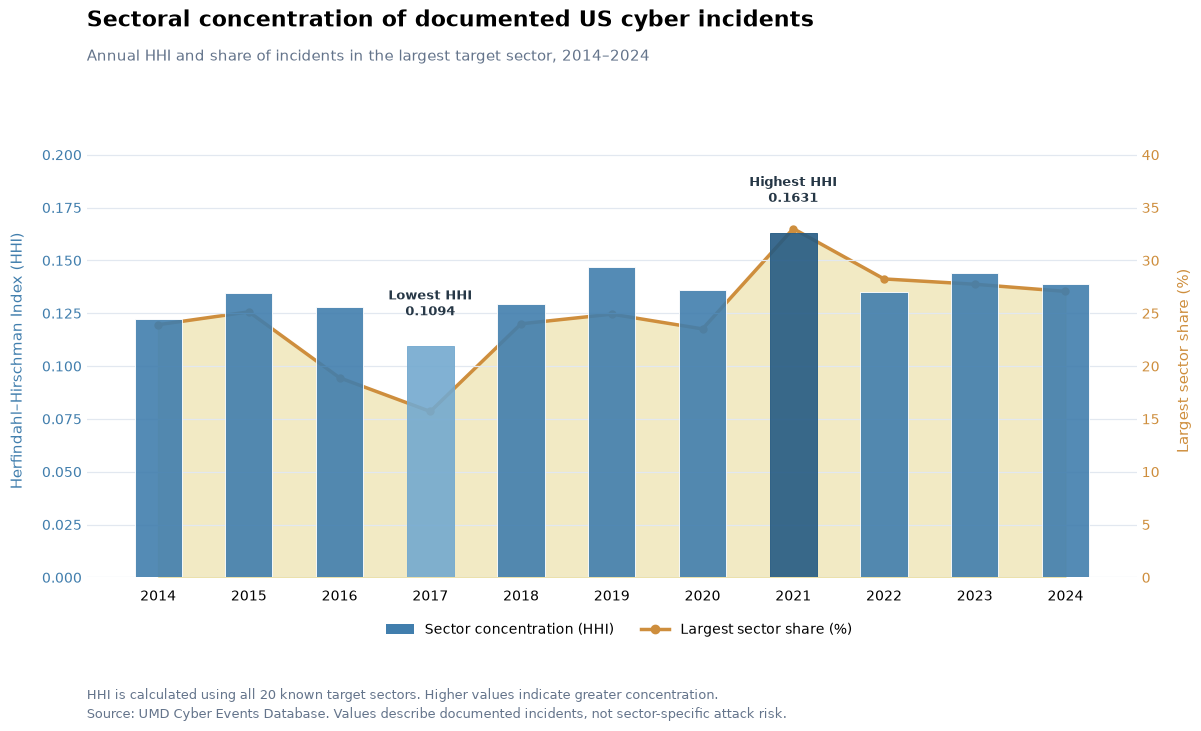

In [21]:
# Visualize annual sector concentration and the largest sector's share.

plot_data = hhi_results.sort_values("year").copy()

years = plot_data["year"].to_numpy()
hhi_values = plot_data["hhi"].to_numpy()
largest_shares = plot_data["largest_sector_share_pct"].to_numpy()

min_idx = np.argmin(hhi_values)
max_idx = np.argmax(hhi_values)

fig, ax_hhi = plt.subplots(figsize=(14, 7.6))
ax_share = ax_hhi.twinx()

# Background area: share of incidents in the largest sector.
ax_share.fill_between(
    years,
    largest_shares,
    0,
    color="#DECA65",
    alpha=0.38,
    zorder=1
)

ax_share.plot(
    years,
    largest_shares,
    color="#CE8E3D",
    linewidth=2.5,
    marker="o",
    markersize=5,
    zorder=2
)

# Foreground bars: annual HHI.
bars = ax_hhi.bar(
    years,
    hhi_values,
    width=0.52,
    color="#417EAD",
    alpha=0.90,
    edgecolor="white",
    linewidth=0.7,
    zorder=3
)

# Emphasize minimum and maximum HHI.
bars[min_idx].set_color("#73A9CF")
bars[max_idx].set_color("#245A83")

for idx, label in [
    (min_idx, "Lowest HHI"),
    (max_idx, "Highest HHI")
]:
    ax_hhi.annotate(
        f"{label}\n{hhi_values[idx]:.4f}",
        xy=(years[idx], hhi_values[idx]),
        xytext=(0, 19),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
        color="#263746"
    )

ax_hhi.set_xticks(years)
ax_hhi.set_xticklabels(years, fontsize=10)

ax_hhi.set_ylim(0, 0.205)
ax_share.set_ylim(0, 41)

ax_hhi.set_ylabel(
    "Herfindahl–Hirschman Index (HHI)",
    fontsize=11,
    color="#417EAD",
    labelpad=12
)

ax_share.set_ylabel(
    "Largest sector share (%)",
    fontsize=11,
    color="#CE8E3D",
    labelpad=12
)

ax_hhi.tick_params(axis="y", colors="#417EAD", length=0)
ax_share.tick_params(axis="y", colors="#CE8E3D", length=0)
ax_hhi.tick_params(axis="x", length=0, pad=9)

ax_hhi.grid(
    axis="y",
    color="#E2E8F0",
    linewidth=0.9,
    zorder=0
)

ax_hhi.set_axisbelow(True)
ax_hhi.patch.set_alpha(0)

for ax in [ax_hhi, ax_share]:
    for spine in ax.spines.values():
        spine.set_visible(False)

# Ensure bars remain visually above the background area.
ax_hhi.set_zorder(3)
ax_share.set_zorder(2)

fig.subplots_adjust(
    left=0.12,
    right=0.87,
    top=0.79,
    bottom=0.22
)

fig.text(
    0.12, 0.945,
    "Sectoral concentration of documented US cyber incidents",
    fontsize=16,
    fontweight="bold",
    ha="left"
)

fig.text(
    0.12, 0.900,
    "Annual HHI and share of incidents in the largest target sector, 2014–2024",
    fontsize=10.5,
    color="#64748B",
    ha="left"
)

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

legend_items = [
    Patch(facecolor="#417EAD", label="Sector concentration (HHI)"),
    Line2D(
        [0], [0],
        color="#CE8E3D",
        linewidth=2.5,
        marker="o",
        label="Largest sector share (%)"
    )
]

fig.legend(
    handles=legend_items,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.125),
    ncol=2,
    frameon=False,
    fontsize=10
)

fig.text(
    0.12, 0.060,
    "HHI is calculated using all 20 known target sectors. Higher values indicate greater concentration.",
    fontsize=9,
    color="#64748B"
)

fig.text(
    0.12, 0.035,
    "Source: UMD Cyber Events Database. Values describe documented incidents, not sector-specific attack risk.",
    fontsize=9,
    color="#64748B"
)

figure_name = "04_sector_concentration_hhi_2014_2024.png"

for output_dir in [
    ROOT / "figures/factors/static",
    ROOT / "ugotovitve/dejavnike",
]:
    output_dir.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        output_dir / figure_name,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()



**Interpretation of the concentration chart**

The highest sectoral concentration was observed in 2021 (HHI = 0.1631). In that year, Health Care and Social Assistance was the dominant sector, accounting for 33.0% of documented incidents (238 out of 721).

The HHI reflects the overall distribution across all 20 known sectors, while the largest-sector share highlights the contribution of the dominant sector. Both measures indicate particularly high concentration in 2021.

Sectoral concentration fluctuated over the study period rather than increasing consistently. These findings describe the distribution of documented incidents in the dataset, not the underlying risk of cyberattacks.



### 4.3 Temporal trend in sector concentration
<div style="text-align: center; font-weight: bold; font-style: italic;">

 Is there a statistically significant monotonic trend in the sectoral concentration of documented US cyber incidents between 2014 and 2024?
</div>

We use Spearman's rank correlation between year and annual HHI to assess whether concentration generally increases or decreases over time.

The hypotheses are:

- **H₀:** There is no monotonic association between year and HHI (\(\rho_s = 0\)).
- **H₁:** There is a monotonic association between year and HHI (\(\rho_s \neq 0\)).

Spearman's correlation does not require a linear relationship or normally distributed HHI values. However, the analysis includes only 11 annual observations, and the usual significance test assumes independent observations. Temporal dependence and changes in incident reporting may affect the results.


In [22]:
# Test the monotonic association between year and annual HHI.

rho, p_value = spearmanr(
    hhi_results["year"],
    hhi_results["hhi"]
)

print(f"Period: {hhi_results['year'].min()}–{hhi_results['year'].max()}")
print(f"Number of years: {len(hhi_results)}")
print(f"Spearman rho: {rho:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Statistically significant (α = 0.05): {p_value < 0.05}")


Period: 2014–2024
Number of years: 11
Spearman rho: 0.7091
P-value: 0.014552
Statistically significant (α = 0.05): True


**Results and interpretation**

Spearman's rank correlation indicated a relatively strong positive association between year and sectoral concentration (ρ = 0.7091, p = 0.0146, n = 11).

This suggests that documented cyber incidents generally became more concentrated across target sectors between 2014 and 2024, despite substantial year-to-year fluctuations.

The lowest concentration occurred in 2017 (HHI = 0.1094), while the highest was observed in 2021 (HHI = 0.1631), when Health Care and Social Assistance accounted for 33.0% of documented incidents.

**Limitations:** The trend analysis is exploratory because only 11 annual observations are available, temporal dependence may violate the assumptions of the significance test, and changes in reporting coverage may affect the observed sector distribution. The findings do not establish changes in actual sector-specific cyberattack risk.


In [23]:
# Calculate sector contributions to annual HHI.

hhi_contributions = pd.DataFrame({
    "year": sector_proportions.index,
    "healthcare_pct": sector_proportions["Health Care and Social Assistance"].values * 100,
    "public_admin_pct": sector_proportions["Public Administration"].values * 100,
    "healthcare_hhi_contribution_pct": (
        sector_proportions["Health Care and Social Assistance"].pow(2)
        / annual_hhi * 100
    ).values,
    "public_admin_hhi_contribution_pct": (
        sector_proportions["Public Administration"].pow(2)
        / annual_hhi * 100
    ).values
})

display(hhi_contributions.round(2))


,year,healthcare_pct,public_admin_pct,healthcare_hhi_contribution_pct,public_admin_hhi_contribution_pct
0,2014,6.16,11.96,3.11,11.71
1,2015,6.08,16.14,2.76,19.38
2,2016,7.56,15.33,4.46,18.37
3,2017,15.70,14.33,22.53,18.75
4,2018,24.00,17.56,44.49,23.81
5,2019,24.92,19.66,42.21,26.28
6,2020,23.52,14.73,40.72,15.97
7,2021,33.01,10.26,66.80,6.46
8,2022,28.25,8.38,59.03,5.19
9,2023,27.75,8.74,53.40,5.30


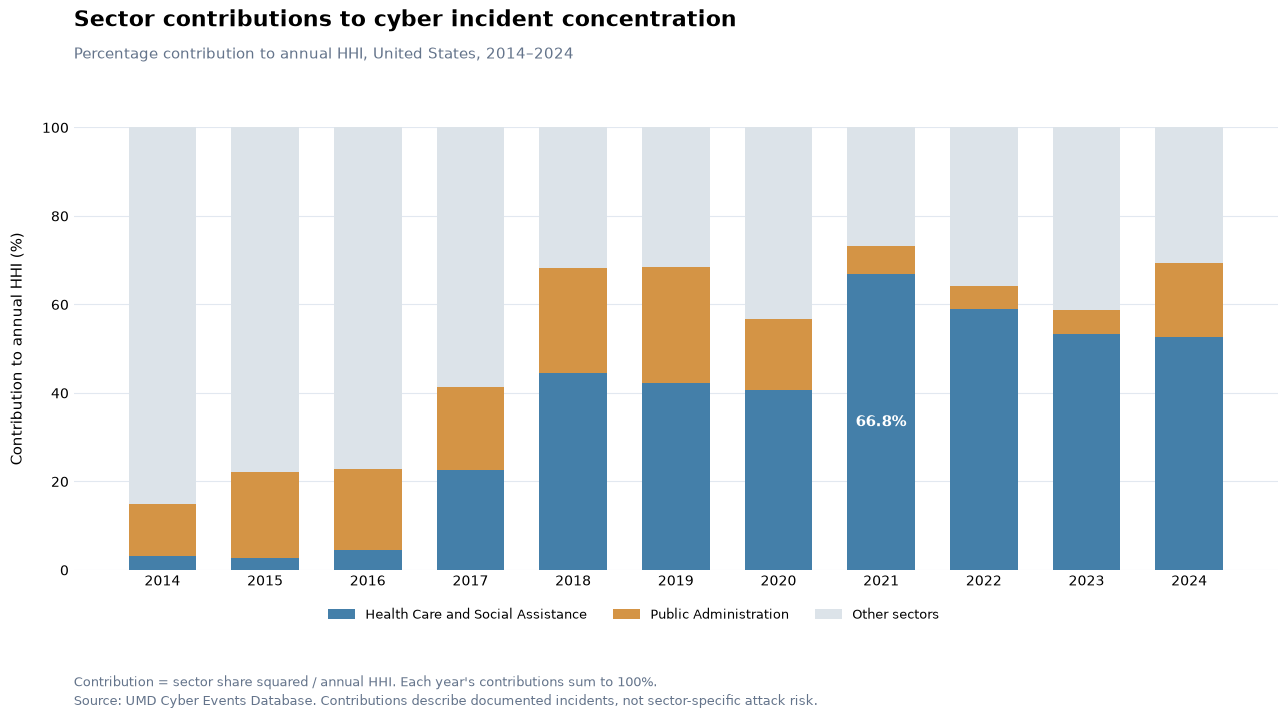

In [24]:
# Visualize sector contributions to annual HHI.

plot_data = hhi_contributions.sort_values("year").copy()

years = plot_data["year"].to_numpy()
healthcare = plot_data["healthcare_hhi_contribution_pct"].to_numpy()
public_admin = plot_data["public_admin_hhi_contribution_pct"].to_numpy()
other_sectors = 100 - healthcare - public_admin

fig, ax = plt.subplots(figsize=(14, 7.5))

bar_width = 0.66

ax.bar(
    years,
    healthcare,
    width=bar_width,
    color="#447FA9",
    label="Health Care and Social Assistance"
)

ax.bar(
    years,
    public_admin,
    bottom=healthcare,
    width=bar_width,
    color="#D49445",
    label="Public Administration"
)

ax.bar(
    years,
    other_sectors,
    bottom=healthcare + public_admin,
    width=bar_width,
    color="#DCE3E9",
    label="Other sectors"
)

# Highlight the healthcare contribution in 2021.
idx_2021 = np.where(years == 2021)[0][0]

ax.text(
    years[idx_2021],
    healthcare[idx_2021] / 2,
    f"{healthcare[idx_2021]:.1f}%",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold",
    color="white"
)

ax.set_xticks(years)
ax.set_xticklabels(years, fontsize=10)
ax.set_ylim(0, 100)

ax.set_ylabel(
    "Contribution to annual HHI (%)",
    fontsize=11,
    labelpad=12
)

ax.tick_params(axis="both", length=0)
ax.grid(axis="y", color="#E2E8F0", linewidth=0.8)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

fig.subplots_adjust(
    left=0.10,
    right=0.96,
    top=0.81,
    bottom=0.22
)

fig.text(
    0.10, 0.945,
    "Sector contributions to cyber incident concentration",
    fontsize=16,
    fontweight="bold",
    ha="left"
)

fig.text(
    0.10, 0.902,
    "Percentage contribution to annual HHI, United States, 2014–2024",
    fontsize=10.5,
    color="#64748B",
    ha="left"
)

fig.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 0.135),
    ncol=3,
    frameon=False,
    fontsize=9.5
)

fig.text(
    0.10, 0.065,
    "Contribution = sector share squared / annual HHI. Each year's contributions sum to 100%.",
    fontsize=9,
    color="#64748B"
)

fig.text(
    0.10, 0.040,
    "Source: UMD Cyber Events Database. Contributions describe documented incidents, not sector-specific attack risk.",
    fontsize=9,
    color="#64748B"
)

figure_name = "04_healthcare_public_administration_hhi_contributions.png"

for output_dir in [
    ROOT / "figures/factors/static",
    ROOT / "ugotovitve/dejavnike",
]:
    output_dir.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        output_dir / figure_name,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()


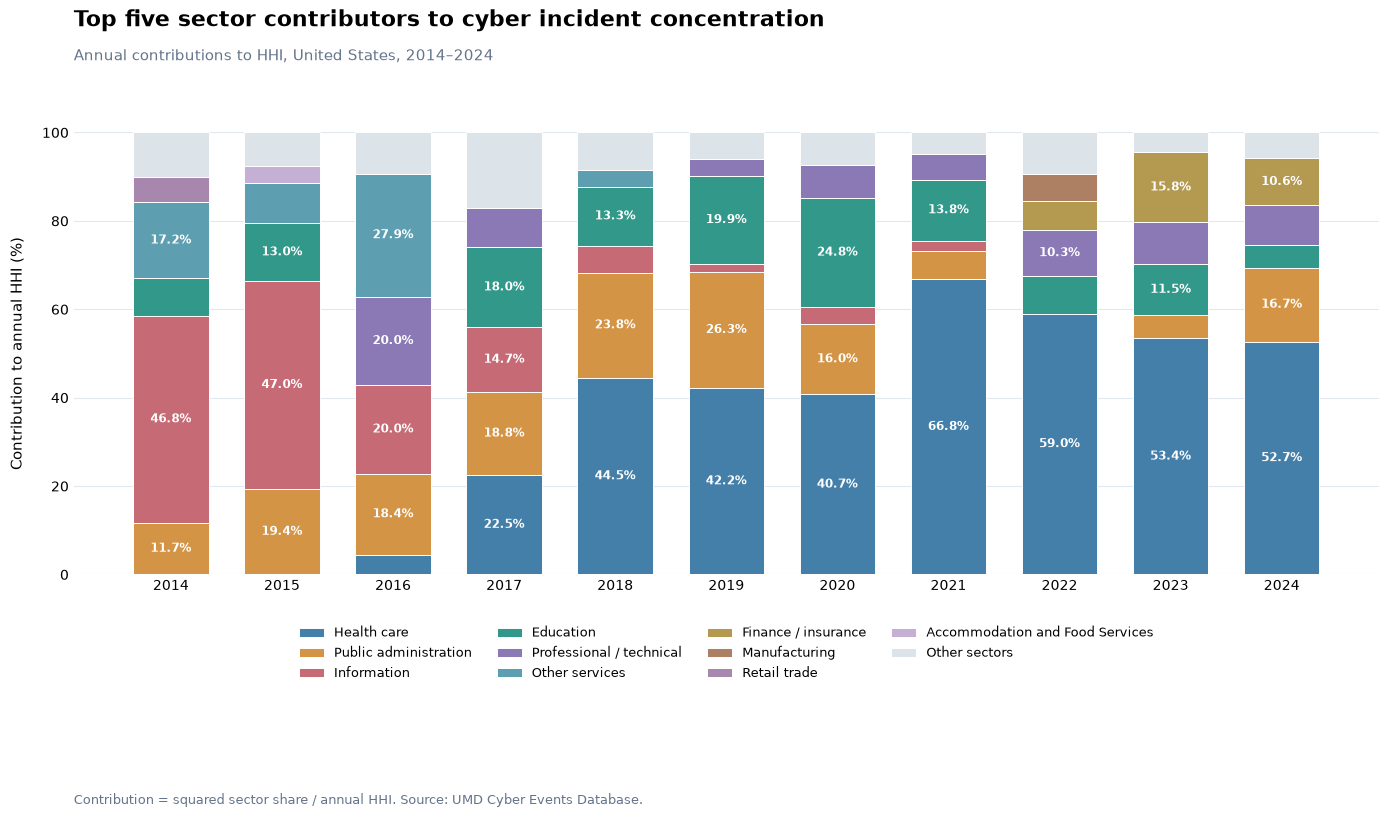

In [25]:

# Visualize the five largest sector contributions to HHI in each year.

contributions = (
    sector_proportions.pow(2)
    .div(annual_hhi, axis=0)
    .mul(100)
)

# Select the top five contributors independently for each year.
top5_mask = contributions.rank(
    axis=1,
    ascending=False,
    method="first"
).le(5)

top5_contributions = contributions.where(top5_mask, 0)

top5_contributions["Other sectors"] = (
    contributions.where(~top5_mask, 0).sum(axis=1)
)

# Keep sector colors consistent across years.
sector_order = (
    top5_contributions
    .drop(columns="Other sectors")
    .sum()
    .sort_values(ascending=False)
)

sector_order = sector_order[sector_order > 0].index.tolist()

sector_colors = {
    "Health Care and Social Assistance": "#447FA9",
    "Public Administration": "#D49445",
    "Educational Services": "#31988A",
    "Professional, Scientific, and Technical Services": "#8B79B6",
    "Information": "#C66B75",
    "Finance and Insurance": "#B49A51",
    "Other Services (except Public Administration)": "#5D9EB1",
    "Manufacturing": "#AD7F63",
    "Arts, Entertainment, and Recreation": "#8FAD70",
    "Retail Trade": "#A887AF",
}

sector_labels = {
    "Health Care and Social Assistance": "Health care",
    "Public Administration": "Public administration",
    "Educational Services": "Education",
    "Professional, Scientific, and Technical Services": "Professional / technical",
    "Information": "Information",
    "Finance and Insurance": "Finance / insurance",
    "Other Services (except Public Administration)": "Other services",
    "Manufacturing": "Manufacturing",
    "Arts, Entertainment, and Recreation": "Arts / entertainment",
    "Retail Trade": "Retail trade",
}

fallback_colors = plt.get_cmap("tab20").colors

for i, sector in enumerate(sector_order):
    if sector not in sector_colors:
        sector_colors[sector] = fallback_colors[i % len(fallback_colors)]

fig, ax = plt.subplots(figsize=(15, 8.5))

years = top5_contributions.index.to_numpy()
bottom = np.zeros(len(years))

for sector in sector_order + ["Other sectors"]:
    values = top5_contributions[sector].to_numpy()

    color = (
        "#DCE3E9"
        if sector == "Other sectors"
        else sector_colors[sector]
    )

    ax.bar(
        years,
        values,
        bottom=bottom,
        width=0.68,
        color=color,
        edgecolor="white",
        linewidth=0.7,
        label=sector_labels.get(sector, sector)
    )

    # Label sufficiently large segments.
    for year, value, base in zip(years, values, bottom):
        if value >= 10 and sector != "Other sectors":
            ax.text(
                year,
                base + value / 2,
                f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=8.5,
                fontweight="bold",
                color="white"
            )

    bottom += values

ax.set_xticks(years)
ax.set_xticklabels(years, fontsize=10)

ax.set_ylim(0, 100)
ax.set_ylabel(
    "Contribution to annual HHI (%)",
    fontsize=11,
    labelpad=12
)

ax.tick_params(axis="both", length=0)
ax.grid(axis="y", color="#E2E8F0", linewidth=0.8)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

fig.subplots_adjust(
    left=0.09,
    right=0.96,
    top=0.83,
    bottom=0.31
)

fig.text(
    0.09, 0.955,
    "Top five sector contributors to cyber incident concentration",
    fontsize=16,
    fontweight="bold",
    ha="left"
)

fig.text(
    0.09, 0.915,
    "Annual contributions to HHI, United States, 2014–2024",
    fontsize=10.5,
    color="#64748B",
    ha="left"
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.09),
    ncol=4,
    frameon=False,
    fontsize=9
)


fig.text(
    0.09, 0.040,
    "Contribution = squared sector share / annual HHI. Source: UMD Cyber Events Database.",
    fontsize=9,
    color="#64748B"
)

figure_name = "04_top5_sector_hhi_contributions_2014_2024.png"

for output_dir in [
    ROOT / "figures/factors/static",
    ROOT / "ugotovitve/dejavnike",
]:
    output_dir.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        output_dir / figure_name,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()


**Sector contributions to concentration**

The increasing concentration of documented incidents was primarily associated with the growing representation of Health Care and Social Assistance. Its contribution to annual HHI increased from 3.11% in 2014 to 52.71% in 2024, reaching 66.80% in 2021.

Public Administration remained an important target sector, but its contribution fluctuated without a similarly clear increase.

These contributions describe the composition of the observed HHI and do not establish causal drivers of the trend.


## 5. Economic structure and target-sector distribution

### 5.1 Data availability and variable selection

<div style="text-align: center; font-weight: bold; font-style: italic;">
 Is the economic structure of the United States associated with the distribution of documented cyber incidents across target sectors between 2014 and 2024?

 </div>

We investigate whether changes in the economic structure of the USA are associated with changes in the distribution of documented cyber incidents across target sectors.

We first examine the available economic indicators and their coverage for 2014–2024. Sector-level comparisons will be selected based on their economic relevance and data availability.

Correlations will be interpreted as associations, not causal effects. Particular attention will be paid to common time trends and the small number of annual observations.


In [26]:
# Inspect national factor availability for the analysis period.

factors_analysis = factors.loc[
    factors["year"].between(2014, 2024)
].copy()

factor_columns = [
    column for column in factors_analysis.columns
    if column != "year"
]

factor_availability = pd.DataFrame({
    "factor": factor_columns,
    "non_missing_years": factors_analysis[factor_columns].notna().sum().values,
    "missing_years": factors_analysis[factor_columns].isna().sum().values,
    "dtype": factors_analysis[factor_columns].dtypes.astype(str).values
})

display(factor_availability)


,factor,non_missing_years,missing_years,dtype
0,country,11,0,str
1,incident_rate,11,0,float64
2,gdp_per_capita,11,0,float64
3,gdp_growth,11,0,float64
4,industry_gdp_pct,11,0,float64
5,services_gdp_pct,11,0,float64
6,unemployment_rate,11,0,float64
7,labor_force_participation,11,0,float64
8,establishment_density,11,0,float64
9,internet_users_pct,11,0,float64


In [27]:
# Align economic indicators with annual target-sector shares.

economic_sector_data = (
    factors_analysis[
        ["year", "industry_gdp_pct", "services_gdp_pct"]
    ]
    .merge(
        annual_sector_shares[
            ["Manufacturing", "Health Care and Social Assistance"]
        ].reset_index(),
        on="year",
        how="inner",
        validate="one_to_one"
    )
    .sort_values("year")
    .reset_index(drop=True)
)

economic_sector_data = economic_sector_data.rename(columns={
    "Manufacturing": "manufacturing_incident_share_pct",
    "Health Care and Social Assistance": "healthcare_incident_share_pct"
})

display(economic_sector_data.round(2))


,year,industry_gdp_pct,services_gdp_pct,manufacturing_incident_share_pct,healthcare_incident_share_pct
0,2014,19.18,79.68,2.90,6.16
1,2015,18.31,80.70,1.06,6.08
2,2016,17.69,81.42,0.67,7.56
3,2017,18.00,81.09,2.48,15.70
4,2018,18.32,80.82,2.67,24.00
5,2019,17.86,81.38,2.37,24.92
6,2020,17.14,82.09,2.09,23.52
7,2021,17.52,81.51,4.85,33.01
8,2022,17.99,80.88,9.02,28.25
9,2023,17.66,81.37,4.55,27.75


### 5.2 Correlation between economic structure and sector incident shares

<div style="text-align: center; font-weight: bold; font-style: italic;">
 Are changes in the economic structure associated with changes in the sectoral distribution of documented cyber incidents?
</div>

We examine two exploratory associations:

- Industry share of GDP vs. Manufacturing incident share.
- Services share of GDP vs. Healthcare incident share.

Spearman's rank correlation is calculated both for annual levels and first differences. First differences help assess whether associations persist beyond common long-term trends.

Because only two comparisons are examined, Benjamini–Hochberg correction is applied within each analysis. Results are interpreted as exploratory associations rather than causal effects.


In [28]:
# Test economic-sector associations in levels and annual changes.

economic_pairs = {
    "Industry GDP vs. Manufacturing incidents": (
        "industry_gdp_pct",
        "manufacturing_incident_share_pct"
    ),
    "Services GDP vs. Healthcare incidents": (
        "services_gdp_pct",
        "healthcare_incident_share_pct"
    )
}

correlation_results = []

for comparison, (factor_col, sector_col) in economic_pairs.items():
    for analysis_type in ["Levels", "First differences"]:
        x = economic_sector_data[factor_col]
        y = economic_sector_data[sector_col]

        if analysis_type == "First differences":
            x = x.diff().dropna()
            y = y.diff().dropna()

        rho, p_value = spearmanr(x, y)

        correlation_results.append({
            "comparison": comparison,
            "analysis": analysis_type,
            "n": len(x),
            "spearman_rho": rho,
            "p_value": p_value
        })

economic_correlations = pd.DataFrame(correlation_results)

for analysis_type in ["Levels", "First differences"]:
    mask = economic_correlations["analysis"].eq(analysis_type)

    economic_correlations.loc[mask, "p_adjusted"] = multipletests(
        economic_correlations.loc[mask, "p_value"],
        method="fdr_bh"
    )[1]

economic_correlations["significant"] = (
    economic_correlations["p_adjusted"] < 0.05
)

display(economic_correlations.round({
    "spearman_rho": 4,
    "p_value": 4,
    "p_adjusted": 4
}))


,comparison,analysis,n,spearman_rho,p_value,p_adjusted,significant
0,Industry GDP vs. Manufacturing incidents,Levels,11,-0.1182,0.7293,0.7293,False
1,Industry GDP vs. Manufacturing incidents,First differences,10,0.7333,0.0158,0.0316,True
2,Services GDP vs. Healthcare incidents,Levels,11,0.4273,0.1899,0.3799,False
3,Services GDP vs. Healthcare incidents,First differences,10,-0.1515,0.6761,0.6761,False


In [29]:
# Assess sensitivity of the significant association to individual annual changes.

changes = economic_sector_data[
    ["year", "industry_gdp_pct", "manufacturing_incident_share_pct"]
].copy()

changes["industry_change"] = changes["industry_gdp_pct"].diff()
changes["manufacturing_change"] = (
    changes["manufacturing_incident_share_pct"].diff()
)

changes = changes.dropna().reset_index(drop=True)

sensitivity_results = []

for i in range(len(changes)):
    subset = changes.drop(index=i)

    rho, p_value = spearmanr(
        subset["industry_change"],
        subset["manufacturing_change"]
    )

    sensitivity_results.append({
        "excluded_year": int(changes.loc[i, "year"]),
        "n": len(subset),
        "spearman_rho": rho,
        "p_value": p_value
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round({
    "spearman_rho": 4,
    "p_value": 4
}))


,excluded_year,n,spearman_rho,p_value
0,2015,9,0.7167,0.0298
1,2016,9,0.7500,0.0199
2,2017,9,0.6667,0.0499
3,2018,9,0.7000,0.0358
4,2019,9,0.7500,0.0199
5,2020,9,0.7667,0.0159
6,2021,9,0.6333,0.0671
7,2022,9,0.6333,0.0671
8,2023,9,0.9000,0.0009
9,2024,9,0.7667,0.0159



**Results and robustness**

We examined two exploratory associations between economic structure and sectoral incident shares using Spearman's correlation in annual levels and first differences.

Only the association between annual changes in industry's share of GDP and Manufacturing's share of documented incidents was statistically significant after Benjamini–Hochberg correction (ρ = 0.7333, adjusted p = 0.0316, n = 10).

No statistically significant association was found in annual levels or between services' GDP share and Healthcare's incident share.

The leave-one-out sensitivity analysis showed that the Manufacturing association remained positive in all ten repetitions (ρ = 0.6333–0.9000). Eight repetitions retained nominal statistical significance (p < 0.05).

**Limitations:** The sample is small, industry GDP covers a broader category than Manufacturing, and changing reporting practices may affect incident shares. The association does not establish causality.


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


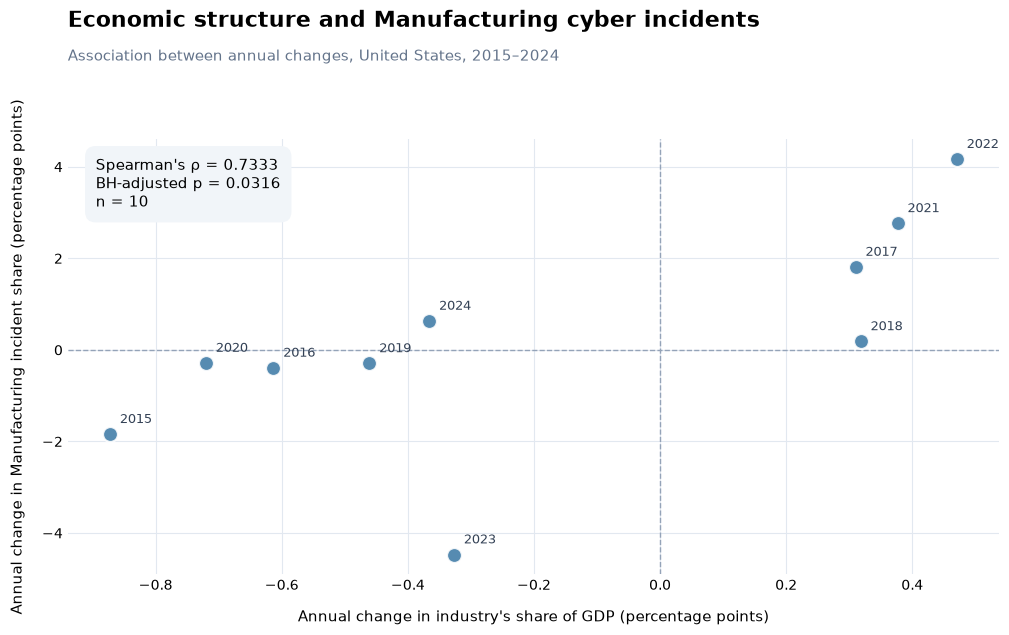

In [30]:
# Visualize annual changes in industry GDP share and Manufacturing incident share.

plot_data = economic_sector_data[
    ["year", "industry_gdp_pct", "manufacturing_incident_share_pct"]
].copy()

plot_data["industry_change"] = plot_data["industry_gdp_pct"].diff()
plot_data["manufacturing_change"] = (
    plot_data["manufacturing_incident_share_pct"].diff()
)

plot_data = plot_data.dropna().reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11.5, 7.5))

x = plot_data["industry_change"].to_numpy()
y = plot_data["manufacturing_change"].to_numpy()
years = plot_data["year"].to_numpy()

ax.scatter(
    x, y,
    s=115,
    color="#447FA9",
    edgecolor="white",
    linewidth=1.5,
    alpha=0.9,
    zorder=3
)

# Label each observation with its year.
for year, x_value, y_value in zip(years, x, y):
    ax.annotate(
        str(year),
        (x_value, y_value),
        xytext=(7, 8),
        textcoords="offset points",
        fontsize=9.5,
        color="#334155"
    )

ax.axhline(0, color="#94A3B8", linewidth=1, linestyle="--")
ax.axvline(0, color="#94A3B8", linewidth=1, linestyle="--")

ax.set_xlabel(
    "Annual change in industry's share of GDP (percentage points)",
    fontsize=11,
    labelpad=12
)

ax.set_ylabel(
    "Annual change in Manufacturing incident share (percentage points)",
    fontsize=11,
    labelpad=12
)

ax.grid(color="#E2E8F0", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0)

for spine in ax.spines.values():
    spine.set_visible(False)

# Display the correlation results.
ax.text(
    0.03, 0.96,
    "Spearman's ρ = 0.7333\n"
    "BH-adjusted p = 0.0316\n"
    "n = 10",
    transform=ax.transAxes,
    fontsize=11,
    fontweight="medium",
    va="top",
    ha="left",
    bbox={
        "boxstyle": "round,pad=0.7",
        "facecolor": "#F1F5F9",
        "edgecolor": "none"
    }
)

fig.subplots_adjust(
    left=0.13,
    right=0.94,
    top=0.80,
    bottom=0.22
)

fig.text(
    0.13, 0.950,
    "Economic structure and Manufacturing cyber incidents",
    fontsize=16,
    fontweight="bold",
    ha="left"
)

fig.text(
    0.13, 0.905,
    "Association between annual changes, United States, 2015–2024",
    fontsize=10.5,
    color="#64748B",
    ha="left"
)


figure_name = "05_industry_manufacturing_first_difference_correlation.png"

for output_dir in [
    ROOT / "figures/factors/static",
    ROOT / "ugotovitve/dejavnike",
]:
    output_dir.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        output_dir / figure_name,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()



## 6. Digital adoption and target-sector distribution

### 6.1 Data preparation and research hypotheses

**Is digital adoption associated with changes in the target-sector distribution of documented US cyber incidents between 2014 and 2024?**

We examine two exploratory associations:

- Internet users (% of population) and the incident share of Information.
- Fixed broadband subscriptions (per 100 people) and the incident share of Finance and Insurance.

Both associations will be examined using Spearman's correlation in annual levels and first differences. First differences provide an additional check against misleading associations driven by common time trends.

The indicators describe national digital adoption, not sector-specific digital exposure. Results will therefore be interpreted as exploratory associations rather than causal relationships.


In [31]:
# Align national digital indicators with annual sector incident shares.

digital_sector_data = (
    factors_analysis[
        ["year", "internet_users_pct", "fixed_broadband_per_100"]
    ]
    .merge(
        annual_sector_shares[
            ["Information", "Finance and Insurance"]
        ].reset_index(),
        on="year",
        how="inner",
        validate="one_to_one"
    )
    .sort_values("year")
    .reset_index(drop=True)
)

digital_sector_data = digital_sector_data.rename(columns={
    "Information": "information_incident_share_pct",
    "Finance and Insurance": "finance_incident_share_pct"
})

display(digital_sector_data.round(2))


,year,internet_users_pct,fixed_broadband_per_100,information_incident_share_pct,finance_incident_share_pct
0,2014,73.00,30.27,23.91,2.17
1,2015,74.55,31.34,25.13,4.23
2,2016,85.54,32.11,16.00,4.67
3,2017,87.27,32.57,12.67,3.58
4,2018,88.50,33.06,8.89,4.89
5,2019,89.43,33.84,5.08,4.07
6,2020,90.34,35.72,7.14,4.40
7,2021,91.27,37.01,6.10,4.44
8,2022,92.73,37.49,4.83,9.45
9,2023,93.53,38.09,4.70,15.10


### 6.2 Spearman correlation analysis

We test two predefined associations between national digital adoption and sectoral incident shares using Spearman's rank correlation.

Both annual levels (n = 11) and first differences (n = 10) are examined. Benjamini–Hochberg correction is applied to the two comparisons within each analysis type.

First differences are used as a sensitivity check for shared time trends. The analysis is exploratory because national digital indicators do not directly measure digital exposure within individual sectors.


In [32]:
# Test digital adoption associations in levels and annual changes.

digital_pairs = {
    "Internet users vs. Information incidents": (
        "internet_users_pct",
        "information_incident_share_pct"
    ),
    "Fixed broadband vs. Finance incidents": (
        "fixed_broadband_per_100",
        "finance_incident_share_pct"
    )
}

digital_results = []

for comparison, (factor_col, sector_col) in digital_pairs.items():
    for analysis_type in ["Levels", "First differences"]:
        x = digital_sector_data[factor_col]
        y = digital_sector_data[sector_col]

        if analysis_type == "First differences":
            x = x.diff().dropna()
            y = y.diff().dropna()

        rho, p_value = spearmanr(x, y)

        digital_results.append({
            "comparison": comparison,
            "analysis": analysis_type,
            "n": len(x),
            "spearman_rho": rho,
            "p_value": p_value
        })

digital_correlations = pd.DataFrame(digital_results)

for analysis_type in ["Levels", "First differences"]:
    mask = digital_correlations["analysis"].eq(analysis_type)

    digital_correlations.loc[mask, "p_adjusted"] = multipletests(
        digital_correlations.loc[mask, "p_value"],
        method="fdr_bh"
    )[1]

digital_correlations["significant"] = (
    digital_correlations["p_adjusted"] < 0.05
)

display(digital_correlations.round({
    "spearman_rho": 4,
    "p_value": 4,
    "p_adjusted": 4
}))


,comparison,analysis,n,spearman_rho,p_value,p_adjusted,significant
0,Internet users vs. Information incidents,Levels,11,-0.9364,0.0000,0.0000,True
1,Internet users vs. Information incidents,First differences,10,-0.4667,0.1739,0.3479,False
2,Fixed broadband vs. Finance incidents,Levels,11,0.7636,0.0062,0.0062,True
3,Fixed broadband vs. Finance incidents,First differences,10,-0.1152,0.7514,0.7514,False



**Results and interpretation**

Both digital adoption indicators showed statistically significant associations with sectoral incident shares in annual levels.

Internet usage was strongly negatively correlated with Information's incident share (Spearman's ρ = −0.9364), while fixed broadband subscriptions were positively correlated with Finance and Insurance's incident share (ρ = 0.7636).

However, neither association remained statistically significant when annual changes were analyzed (BH-adjusted p = 0.3479 and 0.7514, respectively).

This suggests that the correlations in annual levels may largely reflect common time trends rather than direct relationships between digital adoption and sectoral incident distribution.

The findings are exploratory due to the small sample size (11 years), possible temporal dependence, and the use of national indicators rather than sector-specific digital exposure.



## 7. Answers and limitations

### 7.1 Main findings

**Q1: Which sectors account for the most documented incidents?**

Health Care and Social Assistance (1,652 incidents), Educational Services (925), and Public Administration (911) were the three most frequently documented target sectors during 2014–2024.

**Q2: Did sector composition change over time?**

The distribution of documented incidents differed significantly across years (χ²(130) = 1566.632, p < 0.001, Cramér's V = 0.149). Among 154 sector–year comparisons, 39 showed significant deviations after Holm correction. The overall association was relatively weak despite its statistical significance.

**Q3: How did Public Administration compare with other sectors?**

Public Administration differed significantly from 11 of the 12 compared sectors under the equal-representation assumption. Educational Services was the exception (911 vs. 925 incidents, adjusted p = 0.7616). The 50:50 benchmark does not account for differences in sector size or exposure, so these results do not measure relative cyberattack risk.

**Q4: Did sectoral concentration change over time?**

Sectoral concentration generally increased between 2014 and 2024 (Spearman's ρ = 0.7091, p = 0.0146, n = 11), despite annual fluctuations. The highest HHI occurred in 2021 (0.1631), when Healthcare accounted for 33.0% of documented incidents and contributed 66.8% of the annual HHI. Healthcare was the largest target sector in every year from 2017 onward.

**Q5: Was economic structure associated with sectoral incident shares?**

The only significant association among the selected economic comparisons was between annual changes in industry's GDP share and Manufacturing's incident share (ρ = 0.7333, BH-adjusted p = 0.0316, n = 10). The association remained positive in all leave-one-out checks, but the small sample limits confidence in the finding.

**Q6: Was digital adoption associated with sectoral incident shares?**

Internet use was negatively associated with Information's incident share in annual levels (ρ = −0.9364), while fixed broadband was positively associated with Finance and Insurance's incident share (ρ = 0.7636). Neither association remained significant when first differences were analyzed. The level correlations may therefore be influenced by time trends.

### 7.2 Methodological limitations

The analysis concerns publicly documented incidents rather than all cyber incidents occurring in the United States. Reporting coverage, sector classification, and coordinated attack campaigns may influence the observed distribution.

The sector-level tests rely on assumptions about independent observations that may not hold for incidents from the same campaign. Some chi-square expected frequencies remain below five in the primary grouped table.

National economic and digital indicators are not sector-specific measures of exposure. The correlation analyses use only 11 annual observations, or 10 first differences, and may be affected by temporal dependence and multiple exploratory comparisons. Benjamini–Hochberg corrections were applied within the selected comparison families, not across every test conducted in the project.

Consequently, statistically significant associations should not be interpreted as evidence of causality or differences in underlying sector-specific attack risk.



## 8. Export of analysis-ready data

The final dataset combines annual target-sector counts and shares, concentration indicators, and selected national economic and digital factors for 2014–2024.

The exported CSV contains one observation per year. Sector shares are expressed as percentages, while HHI is reported on the 0–1 scale.


In [33]:
# Export the annual sector and national-factor analysis dataset.

sector_shares_export = (
    annual_sector_shares
    .add_prefix("sector_share_pct__")
    .rename_axis("year")
    .reset_index()
)

sector_counts_export = (
    annual_sector_counts
    .add_prefix("sector_count__")
    .rename_axis("year")
    .reset_index()
)

national_factors_export = factors_analysis.drop(
    columns=["country", "incident_rate"],
    errors="ignore"
)

export_data = (
    hhi_results
    .merge(
        sector_counts_export,
        on="year",
        validate="one_to_one"
    )
    .merge(
        sector_shares_export,
        on="year",
        validate="one_to_one"
    )
    .merge(
        hhi_contributions.drop(columns=[
            "healthcare_pct",
            "public_admin_pct"
        ]),
        on="year",
        validate="one_to_one"
    )
    .merge(
        national_factors_export,
        on="year",
        validate="one_to_one"
    )
    .sort_values("year")
    .reset_index(drop=True)
)

# Validate the exported dataset.
assert len(export_data) == 11
assert export_data["year"].tolist() == list(range(2014, 2025))
assert export_data["year"].is_unique
assert export_data.notna().all().all()

share_columns = [
    column for column in export_data.columns
    if column.startswith("sector_share_pct__")
]

assert np.allclose(
    export_data[share_columns].sum(axis=1),
    100
)

output_dir = ROOT / "data/processed/factors"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir / "usa_target_sector_factors_2014_2024.csv"
)

export_data.to_csv(
    output_path,
    index=False,
    float_format="%.8f"
)

print(f"Exported: {output_path}")
print(f"Rows: {len(export_data)}")
print(f"Columns: {len(export_data.columns)}")
print(f"Missing values: {export_data.isna().sum().sum()}")

display(export_data.head())


Exported: c:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\data\processed\factors\usa_target_sector_factors_2014_2024.csv
Rows: 11
Columns: 57
Missing values: 0


,year,total_incidents,hhi,effective_number_of_sectors,largest_sector_share_pct,largest_sector,sector_count__Accommodation and Food Services,sector_count__Administrative and Support and Waste Management and Remediation Services,"sector_count__Agriculture, Forestry, Fishing and Hunting","sector_count__Arts, Entertainment, and Recreation",...,public_admin_hhi_contribution_pct,gdp_per_capita,gdp_growth,industry_gdp_pct,services_gdp_pct,unemployment_rate,labor_force_participation,establishment_density,internet_users_pct,fixed_broadband_per_100
0,2014,276,0.122086,8.190968,23.913043,Information,14,5,1,7,...,11.709677,55153.394018,2.523820,19.178768,79.682111,6.168,62.447,292.687081,73.000000,30.270921
1,2015,378,0.134361,7.442650,25.132275,Information,27,4,0,11,...,19.382227,56849.469792,2.945550,18.306682,80.697713,5.280,62.267,295.338173,74.554202,31.341213
2,2016,450,0.127970,7.814309,18.888889,Other Services (except Public Administration),17,0,0,22,...,18.372308,57976.628204,1.819451,17.693637,81.415692,4.869,62.431,298.991678,85.544421,32.114401
3,2017,363,0.109442,9.137300,15.702479,Health Care and Social Assistance,16,2,0,26,...,18.750433,60047.719073,2.457622,18.003940,81.094377,4.355,62.548,300.531738,87.274889,32.570284
4,2018,450,0.129462,7.724291,24.000000,Health Care and Social Assistance,19,6,0,24,...,23.806073,62875.666138,2.966505,18.322340,80.820231,3.896,62.592,304.149105,88.498903,33.055918
